<a href="https://colab.research.google.com/github/zish-s/ML-Zoomcamp-HW/blob/main/homework_02_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv(
    'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
)

In [3]:
columns = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year',
    'fuel_efficiency_mpg'
]

df = df[columns]

EDA

In [4]:
df['fuel_efficiency_mpg'].describe()

,fuel_efficiency_mpg
count,10000.000000
mean,29.997700
std,2.930245
min,19.800000
25%,28.000000
50%,30.000000
75%,31.900000
max,41.200000


<Axes: >

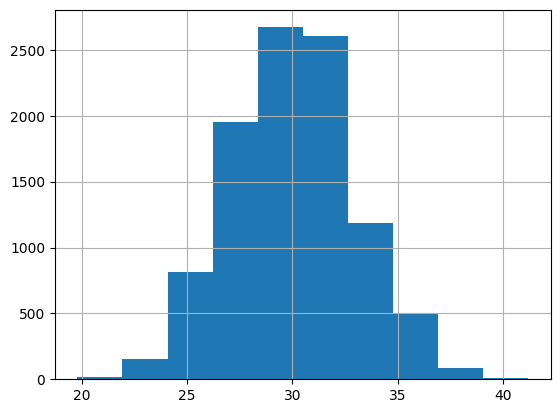

In [5]:
df['fuel_efficiency_mpg'].hist()

Columns with missing values

In [6]:
df.columns[df.isnull().any()]

Index(['horsepower'], dtype='object')

median horsepower

In [7]:
df['horsepower'].median()

254.0

Train, Split, Validate

In [8]:
df = df.copy()

In [9]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)

idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [10]:
def train_linear_regression(X, y):
    X = np.column_stack([np.ones(X.shape[0]), X])

    XTX = X.T @ X
    XTX_inv = np.linalg.inv(XTX)

    w = XTX_inv @ X.T @ y

    return w

In [11]:
def predict(X, w):
    X = np.column_stack([np.ones(X.shape[0]), X])
    return X @ w

In [12]:
#rmse

def rmse(y, y_pred):
    error = y_pred - y
    mse = np.mean(error ** 2)
    return np.sqrt(mse)

Fill missing values with 0 vs mean

In [13]:
target = 'fuel_efficiency_mpg'

features = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year'
]

In [14]:
train_zero = df_train.copy()
val_zero = df_val.copy()

train_zero[features] = train_zero[features].fillna(0)
val_zero[features] = val_zero[features].fillna(0)

In [15]:
X_train = train_zero[features].values
y_train = train_zero[target].values

w = train_linear_regression(X_train, y_train)

In [16]:
X_val = val_zero[features].values
y_val = val_zero[target].values

y_pred = predict(X_val, w)

score_zero = rmse(y_val, y_pred)

round(score_zero, 3)

np.float64(2.205)

In [17]:
train_mean = df_train[features].mean()

In [18]:
train_mean_data = df_train.copy()
val_mean_data = df_val.copy()

train_mean_data[features] = train_mean_data[features].fillna(train_mean)
val_mean_data[features] = val_mean_data[features].fillna(train_mean)

In [19]:
X_train = train_mean_data[features].values
y_train = train_mean_data[target].values

w = train_linear_regression(X_train, y_train)

In [20]:
X_val = val_mean_data[features].values
y_val = val_mean_data[target].values

y_pred = predict(X_val, w)

score_mean = rmse(y_val, y_pred)

round(score_mean, 3)

np.float64(2.202)

In [21]:
print("RMSE with 0:", round(score_zero, 3))
print("RMSE with mean:", round(score_mean, 3))

RMSE with 0: 2.205
RMSE with mean: 2.202


Regularized linear regression

In [22]:
r_values = [0, 0.01, 0.1, 1, 5, 10, 100]

In [23]:
train = df_train.copy()
val = df_val.copy()

train[features] = train[features].fillna(0)
val[features] = val[features].fillna(0)

In [24]:
def train_linear_regression_reg(X, y, r):
    X = np.column_stack([np.ones(X.shape[0]), X])

    XTX = X.T @ X

    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)

    w = XTX_inv @ X.T @ y

    return w

In [25]:
X_train = train[features].values
y_train = train[target].values

X_val = val[features].values
y_val = val[target].values

In [26]:
for r in r_values:
    w = train_linear_regression_reg(X_train, y_train, r)

    y_pred = predict(X_val, w)

    score = rmse(y_val, y_pred)

    print(r, round(score, 4))

0 2.2053
0.01 2.2058
0.1 2.2241
1 2.3492
5 2.4094
10 2.4195
100 2.4292


rmse standard deviation

In [27]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [28]:
scores = []

for seed in seeds:

    n = len(df)

    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)

    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    # Fill missing values with 0
    df_train = df_train.copy()
    df_val = df_val.copy()

    df_train[features] = df_train[features].fillna(0)
    df_val[features] = df_val[features].fillna(0)

    # Train
    X_train = df_train[features].values
    y_train = df_train[target].values

    w = train_linear_regression(X_train, y_train)

    # Validate
    X_val = df_val[features].values
    y_val = df_val[target].values

    y_pred = predict(X_val, w)

    score = rmse(y_val, y_pred)

    scores.append(score)

    print(seed, score)

0 2.2392041430461265
1 2.202112821083884
2 2.1634197787530947
3 2.2043588768539215
4 2.2018800943311554
5 2.2457851509085134
6 2.2697212079524043
7 2.190794599933443
8 2.216611201686444
9 2.207036592817896


In [29]:
std = np.std(scores)

round(std, 3)

np.float64(0.029)

evaluation on test

In [30]:
np.random.seed(9)

n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [31]:
df_train_full = pd.concat([df_train, df_val])

In [32]:
df_train_full = df_train_full.copy()
df_test = df_test.copy()

df_train_full[features] = df_train_full[features].fillna(0)
df_test[features] = df_test[features].fillna(0)

In [33]:
r = 0.001

In [34]:
X_train = df_train_full[features].values
y_train = df_train_full[target].values

w = train_linear_regression_reg(X_train, y_train, r)

In [35]:
X_test = df_test[features].values
y_test = df_test[target].values

y_pred = predict(X_test, w)

score = rmse(y_test, y_pred)

round(score, 3)

np.float64(2.236)

In [36]:
print('--- Question 1: Missing values ---')
print(df[features].isnull().sum())

print('\n--- Question 2: Median for horsepower ---')
print(df['horsepower'].median())

print('\n--- Question 3: Filling NAs ---')
print(f'RMSE with 0: {score_zero:.3f}')
print(f'RMSE with mean: {score_mean:.3f}')

print('\n--- Question 4: Best regularization ---')
for r in r_values:
    w = train_linear_regression_reg(X_train, y_train, r)
    # Note: the validation score loop used validation sets filled with 0
    # We will compute it using the validation dataset defined for validation
    v_zero = df_val.copy()
    v_zero[features] = v_zero[features].fillna(0)
    X_val_reg = v_zero[features].values
    y_val_reg = v_zero[target].values
    w_reg = train_linear_regression_reg(train[features].values, train[target].values, r)
    y_pred_reg = predict(X_val_reg, w_reg)
    print(f'r={r:5}: RMSE={rmse(y_val_reg, y_pred_reg):.4f}')

print('\n--- Question 5: RMSE standard deviation ---')
print(f'Standard deviation: {std:.3f}')

print('\n--- Question 6: Evaluation on test ---')
print(f'Test RMSE: {score:.3f}')

--- Question 1: Missing values ---
engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
dtype: int64

--- Question 2: Median for horsepower ---
254.0

--- Question 3: Filling NAs ---
RMSE with 0: 2.205
RMSE with mean: 2.202

--- Question 4: Best regularization ---
r=    0: RMSE=2.2066
r= 0.01: RMSE=2.2063
r=  0.1: RMSE=2.2193
r=    1: RMSE=2.3360
r=    5: RMSE=2.3945
r=   10: RMSE=2.4044
r=  100: RMSE=2.4139

--- Question 5: RMSE standard deviation ---
Standard deviation: 0.029

--- Question 6: Evaluation on test ---
Test RMSE: 2.236
